In [1]:
import math,os
from zipfile import ZipFile
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from sklearn.metrics import (roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)
from pathlib import Path

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# --- validated chart tokens (light mode) --------------------------------
SURFACE, INK, INK2, MUTED, GRID, AXLINE = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7")
C_LEGIT, C_FRAUD, C_THR = "#2a78d6", "#eb6834", "#d03b3b"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "figure.dpi": 120,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXLINE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "legend.frameon": False, "lines.linewidth": 2.0,
    "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
})

In [2]:
datapath=os.path.join(Path.cwd(),'data')
zippath=os.path.join(datapath,'archive (1).zip')

with ZipFile(zippath) as archive :
    archive.extractall(datapath)

In [3]:

# def make_data(n_normal=6000, n_anom=600, D=20, true_latent=3, noise=0.25):
#     """Normal points live near a `true_latent`-dim linear manifold in R^D.
#     Anomalies are generated from a DIFFERENT manifold, so every individual
#     coordinate looks plausible but the joint pattern is wrong."""
#     A = np.random.randn(true_latent, D)
#     s = np.random.randn(n_normal, true_latent)
#     X_norm = s @ A + noise * np.random.randn(n_normal, D)

#     B = np.random.randn(true_latent, D)          # different subspace
#     s2 = np.random.randn(n_anom, true_latent)
#     X_anom = s2 @ B + noise * np.random.randn(n_anom, D)

#     # keep marginal scale comparable so the task is not trivially easy
#     X_anom *= X_norm.std() / X_anom.std()
#     return X_norm.astype(np.float32), X_anom.astype(np.float32)

In [4]:
def make_data(path="data/creditcard.csv"):
    """Legit rows (shuffled) and fraud rows from the ULB credit-card dataset.
    Fraud is returned separately and never enters training."""
    df = pd.read_csv(path)
    y = df.pop("Class").to_numpy().astype(int)

    df["Amount"] = np.log1p(df["Amount"])   # heavy right tail -> Gaussian NLL
    df = df.drop(columns=["Time"])          # global clock, not a feature

    X = df.to_numpy(dtype=np.float32)
    rng = np.random.default_rng(SEED)
    X_legit = X[y == 0]
    X_legit = X_legit[rng.permutation(len(X_legit))]   # file is time-ordered
    return X_legit, X[y == 1], list(df.columns)


legit (284315, 29)  fraud (492, 29)  prevalence 0.1727%


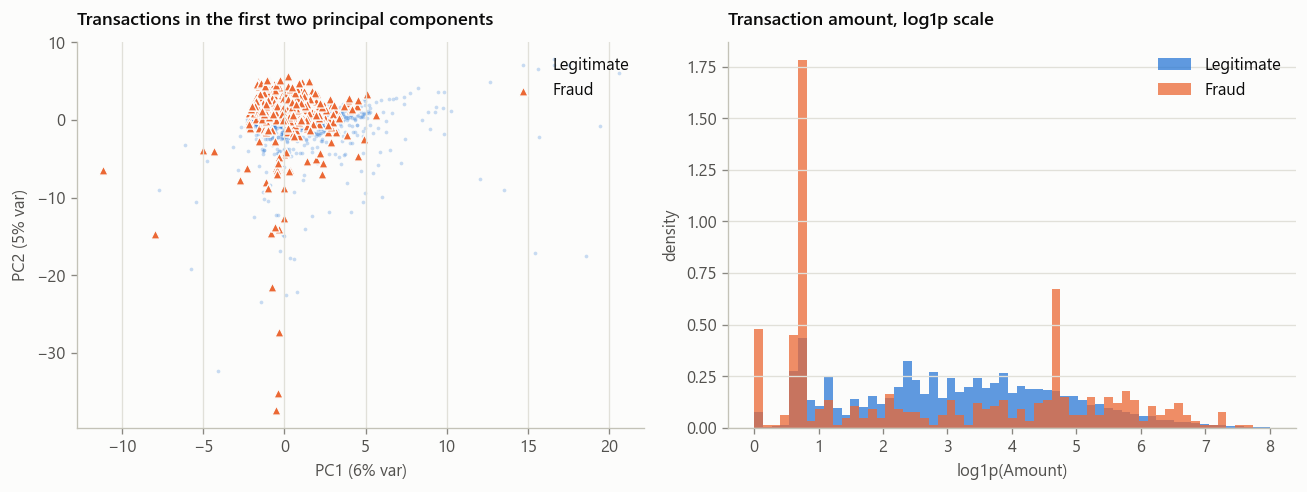

In [5]:
Xl, Xf, COLS = make_data()
print(f"legit {Xl.shape}  fraud {Xf.shape}  prevalence {len(Xf)/(len(Xl)+len(Xf)):.4%}")

rng = np.random.default_rng(SEED)
sub = Xl[rng.choice(len(Xl), 8000, replace=False)]
mu_, sd_ = sub.mean(0), sub.std(0) + 1e-8
p = PCA(n_components=2, random_state=SEED).fit((sub - mu_) / sd_)
Zl, Zf = p.transform((sub - mu_) / sd_), p.transform((Xf - mu_) / sd_)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(*Zl.T, s=5, c=C_LEGIT, alpha=.25, lw=0, label="Legitimate")
ax[0].scatter(*Zf.T, s=30, c=C_FRAUD, marker="^", lw=.8,
              edgecolor=SURFACE, label="Fraud")
ax[0].set(title="Transactions in the first two principal components",
          xlabel=f"PC1 ({p.explained_variance_ratio_[0]:.0%} var)",
          ylabel=f"PC2 ({p.explained_variance_ratio_[1]:.0%} var)")
ax[0].grid(axis="both"); ax[0].legend(loc="upper right")

bins = np.linspace(0, np.log1p(3000), 60)
ax[1].hist(Xl[:, COLS.index("Amount")], bins=bins, density=True,
           color=C_LEGIT, alpha=.75, label="Legitimate")
ax[1].hist(Xf[:, COLS.index("Amount")], bins=bins, density=True,
           color=C_FRAUD, alpha=.75, label="Fraud")
ax[1].set(title="Transaction amount, log1p scale",
          xlabel="log1p(Amount)", ylabel="density")
ax[1].legend()
fig.tight_layout(); plt.show()


In [6]:
class VAE(nn.Module):
    def __init__(self, in_dim, hidden=(64, 32), latent=4):
        super().__init__()

        enc, prev = [], in_dim
        for h in hidden:
            enc += [nn.Linear(prev, h), nn.SiLU()]
            prev = h
        self.enc = nn.Sequential(*enc)
        self.fc_mu = nn.Linear(prev, latent)
        self.fc_logvar = nn.Linear(prev, latent)

        dec, prev = [], latent
        for h in reversed(hidden):
            dec += [nn.Linear(prev, h), nn.SiLU()]
            prev = h
        self.dec = nn.Sequential(*dec)
        self.fc_out = nn.Linear(prev, in_dim)

        # learned global observation noise:  log of sigma_x^2
        # this auto-balances reconstruction against KL, so beta stays at 1
        self.log_var_x = nn.Parameter(torch.zeros(1))

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h).clamp(-8.0, 8.0)

    def decode(self, z):
        return self.fc_out(self.dec(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparam
        return self.decode(z), mu, logvar


In [7]:
LOG2PI = math.log(2 * math.pi)


def elbo_loss(x, x_hat, mu, logvar, log_var_x, beta=1.0):
    nll = 0.5 * (((x - x_hat) ** 2) / log_var_x.exp()
                 + log_var_x + LOG2PI).sum(1)                    # (B,)
    kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)   # (B,)
    return (nll + beta * kl).mean(), nll.mean().item(), kl.mean().item()

In [8]:
@torch.no_grad()
def neg_log_likelihood(model, x, L=64):
    """IWAE bound with L posterior samples. Lower = more normal."""
    mu, logvar = model.encode(x)                       # (B,k)
    std = torch.exp(0.5 * logvar)
    eps = torch.randn(L, *mu.shape, device=x.device)   # (L,B,k)
    z = mu + std * eps
    B, k = mu.shape

    x_hat = model.decode(z.reshape(L * B, k)).reshape(L, B, -1)
    lv = model.log_var_x

    log_p_x_z = -0.5 * (((x - x_hat) ** 2) / lv.exp() + lv + LOG2PI).sum(-1)  # log p(x|z)
    log_p_z = -0.5 * (z ** 2 + LOG2PI).sum(-1) # log p(z)
    log_q_z = -0.5 * (eps ** 2 + logvar + LOG2PI).sum(-1) #log_p_x_z + log_p_z - log_q_z

    log_w = log_p_x_z + log_p_z - log_q_z              # (L,B)
    return -(torch.logsumexp(log_w, 0) - math.log(L))  # (B,)


@torch.no_grad()
def score_all(model, X, batch=1024, L=64):
    model.eval()
    return torch.cat([neg_log_likelihood(model, X[i:i + batch].to(DEVICE), L).cpu()
                      for i in range(0, len(X), batch)])


In [9]:
def roc_auc(scores, labels):
    order = np.argsort(scores)
    ranks = np.empty_like(order, dtype=float)
    ranks[order] = np.arange(1, len(scores) + 1)
    n_pos, n_neg = labels.sum(), (1 - labels).sum()
    return (ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

In [10]:
# def main():
#     X_norm, X_anom = make_data()
#     D = X_norm.shape[1]

#     n_tr = int(0.7 * len(X_norm))
#     n_va = int(0.15 * len(X_norm))
#     tr, va, te_n = X_norm[:n_tr], X_norm[n_tr:n_tr + n_va], X_norm[n_tr + n_va:]

#     # standardise with TRAIN statistics only — never touch anomalies here
#     mu_, sd_ = tr.mean(0), tr.std(0) + 1e-8
#     z = lambda a: torch.from_numpy((a - mu_) / sd_)
#     tr, va, te_n, te_a = z(tr), z(va), z(te_n), z(X_anom)

#     loader = DataLoader(TensorDataset(tr), batch_size=256, shuffle=True)
#     model = VAE(D, hidden=(64, 32), latent=4).to(DEVICE)
#     opt = torch.optim.Adam(model.parameters(), lr=1e-3)

#     EPOCHS, WARMUP = 120, 30
#     best, best_state, patience = float("inf"), None, 0

#     for ep in range(1, EPOCHS + 1):
#         model.train()
#         beta = min(1.0, ep / WARMUP)          # KL warm-up: fights collapse
#         for (xb,) in loader:
#             xb = xb.to(DEVICE)
#             x_hat, m, lv = model(xb)
#             loss, nll, kl = elbo_loss(xb, x_hat, m, lv, model.log_var_x, beta)
#             opt.zero_grad(set_to_none=True)
#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
#             opt.step()

#         val = score_all(model, va, L=16).mean().item()
#         if ep % 20 == 0 or ep == 1:
#             print(f"ep {ep:3d} | beta {beta:.2f} | nll {nll:7.2f} | "
#                   f"kl {kl:6.2f} | val -logp {val:7.2f}")

#         if ep > WARMUP:                        # early stop on held-out normal
#             if val < best - 1e-3:
#                 best, best_state, patience = val, \
#                     {k: v.detach().clone() for k, v in model.state_dict().items()}, 0
#             else:
#                 patience += 1
#                 if patience >= 20:
#                     print(f"early stop at epoch {ep}")
#                     break
#     if best_state:
#         model.load_state_dict(best_state)
#     s_val = score_all(model, va).numpy()
#     thr = np.percentile(s_val, 99)             # 1% false-positive budget
#     print(f"\nKL per active latent dim: "
#             f"{[round(v,2) for v in per_dim_kl(model, va)]}")
#     print(f"threshold (99th pct of normal) = {thr:.2f}")

#     # ---- evaluate ---------------------------------------------------------
#     s_n = score_all(model, te_n).numpy()
#     s_a = score_all(model, te_a).numpy()
#     scores = np.concatenate([s_n, s_a])
#     labels = np.concatenate([np.zeros(len(s_n)), np.ones(len(s_a))])

#     print(f"AUC          = {roc_auc(scores, labels):.4f}")
#     print(f"recall       = {(s_a > thr).mean():.4f}")
#     print(f"false alarms = {(s_n > thr).mean():.4f}")
#     print(f"mean -logp   normal {s_n.mean():8.2f} | anomalous {s_a.mean():8.2f}")


In [11]:
from typing import TypedDict


class Splits(TypedDict):
    """Typed so sp["va"] is known to be a Tensor, not Tensor | list | int.
    Without this the mixed-value dict makes Pylance flag every .numpy() call."""
    va: torch.Tensor
    te_n: torch.Tensor
    te_a: torch.Tensor
    cols: list[str]
    best_ep: int


# ---- ORIGINAL SIGNATURE (kept for reference) -------------------------------
# def train_vae(epochs=40, warmup=8, hidden=(128, 64), latent=12,
#               lr=1e-3, batch=512, patience_max=8, diag_n=4000):
# ---- TUNING: added `data=` so a sweep can pass pre-loaded arrays ------------
def train_vae(epochs=40, warmup=8, hidden=(128, 64), latent=12,
              lr=1e-3, batch=512, patience_max=8, diag_n=4000, data=None):
    # X_legit, X_fraud, cols = make_data()   # original: re-reads the 150 MB CSV every call
    X_legit, X_fraud, cols = make_data() if data is None else data
    D = X_legit.shape[1]

    n_tr, n_va = int(.7 * len(X_legit)), int(.15 * len(X_legit))
    tr_r, va_r = X_legit[:n_tr], X_legit[n_tr:n_tr + n_va]
    te_r = X_legit[n_tr + n_va:]

    mu_, sd_ = tr_r.mean(0), tr_r.std(0) + 1e-8      # TRAIN stats only
    z = lambda a: torch.from_numpy((a - mu_) / sd_)
    tr, va, te_n, te_a = z(tr_r), z(va_r), z(te_r), z(X_fraud)
    print(f"train {len(tr)} | val {len(va)} | test-legit {len(te_n)} | test-fraud {len(te_a)}")
    print(f"{len(tr)//batch + 1} steps/epoch -> {(len(tr)//batch + 1)*epochs} total updates")

    loader = DataLoader(TensorDataset(tr), batch_size=batch, shuffle=True)
    model = VAE(D, hidden=hidden, latent=latent).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {k: [] for k in ("epoch", "beta", "train", "nll", "kl", "val", "sigma_x", "auc")}
    best, best_state, best_ep, patience = float("inf"), None, 0, 0

    dn = te_n[:diag_n]
    dlab = np.r_[np.zeros(len(dn)), np.ones(len(te_a))]

    for ep in range(1, epochs + 1):
        model.train()
        beta = min(1.0, ep / warmup)
        tot = tn = tk = 0.0; nb = 0
        for (xb,) in loader:
            xb = xb.to(DEVICE)
            x_hat, m, lv = model(xb)
            loss, nll, kl = elbo_loss(xb, x_hat, m, lv, model.log_var_x, beta)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tot += loss.item(); tn += nll; tk += kl; nb += 1

        val = score_all(model, va, L=8).mean().item()
        sig = float(model.log_var_x.detach().exp().sqrt())
        # AUC* uses fraud labels: DIAGNOSTIC ONLY, never for model selection
        ds = np.r_[score_all(model, dn, L=8).numpy(), score_all(model, te_a, L=8).numpy()]
        auc = roc_auc(ds, dlab)

        for k, v in zip(hist, (ep, beta, tot/nb, tn/nb, tk/nb, val, sig, auc)):
            hist[k].append(v)
        print(f"ep {ep:3d} | beta {beta:.2f} | train {tot/nb:9.2f} | nll {tn/nb:8.2f} "
              f"| kl {tk/nb:5.2f} | val -logp {val:8.2f} | sigma_x {sig:.3f} | AUC* {auc:.4f}")

        if ep > warmup:
            if val < best - 1e-3:
                best, best_ep, patience = val, ep, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                patience += 1
                if patience >= patience_max:
                    print(f"early stop at epoch {ep}"); break

    if best_state:
        model.load_state_dict(best_state)
        print(f"restored best epoch {best_ep} (val -logp {best:.2f})")
    return model, hist, Splits(va=va, te_n=te_n, te_a=te_a, cols=cols, best_ep=best_ep)


def evaluate(model, sp: Splits, L=64):
    s = {"va":   score_all(model, sp["va"],   L=L).numpy(),
         "te_n": score_all(model, sp["te_n"], L=L).numpy(),
         "te_a": score_all(model, sp["te_a"], L=L).numpy()}
    s["scores"] = np.r_[s["te_n"], s["te_a"]]
    s["labels"] = np.r_[np.zeros(len(s["te_n"])), np.ones(len(s["te_a"]))]
    return s


In [12]:
@torch.no_grad()
def per_dim_kl(model, X, n=2048):
    """Diagnostic: a dimension whose KL is ~0 has collapsed to the prior."""
    mu, lv = model.encode(X[:n].to(DEVICE))
    return (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).mean(0).cpu().tolist()




In [13]:
model, hist, sp = train_vae()
print("\nKL per latent dim:", [round(v, 2) for v in per_dim_kl(model, sp["va"])])
S = evaluate(model, sp)


train 199020 | val 42647 | test-legit 42648 | test-fraud 492
389 steps/epoch -> 15560 total updates
ep   1 | beta 0.12 | train     34.44 | nll    32.89 | kl 12.36 | val -logp    43.34 | sigma_x 0.815 | AUC* 0.9567
ep   2 | beta 0.25 | train     27.86 | nll    23.88 | kl 15.89 | val -logp    37.06 | sigma_x 0.669 | AUC* 0.9579
ep   3 | beta 0.38 | train     25.46 | nll    19.48 | kl 15.95 | val -logp    33.15 | sigma_x 0.563 | AUC* 0.9587
ep   4 | beta 0.50 | train     24.32 | nll    16.21 | kl 16.24 | val -logp    30.62 | sigma_x 0.487 | AUC* 0.9593
ep   5 | beta 0.62 | train     24.18 | nll    13.91 | kl 16.43 | val -logp    28.83 | sigma_x 0.435 | AUC* 0.9596
ep   6 | beta 0.75 | train     24.80 | nll    12.47 | kl 16.44 | val -logp    27.42 | sigma_x 0.400 | AUC* 0.9606
ep   7 | beta 0.88 | train     25.81 | nll    11.55 | kl 16.31 | val -logp    26.46 | sigma_x 0.377 | AUC* 0.9591
ep   8 | beta 1.00 | train     27.17 | nll    11.12 | kl 16.05 | val -logp    25.67 | sigma_x 0.363 | 

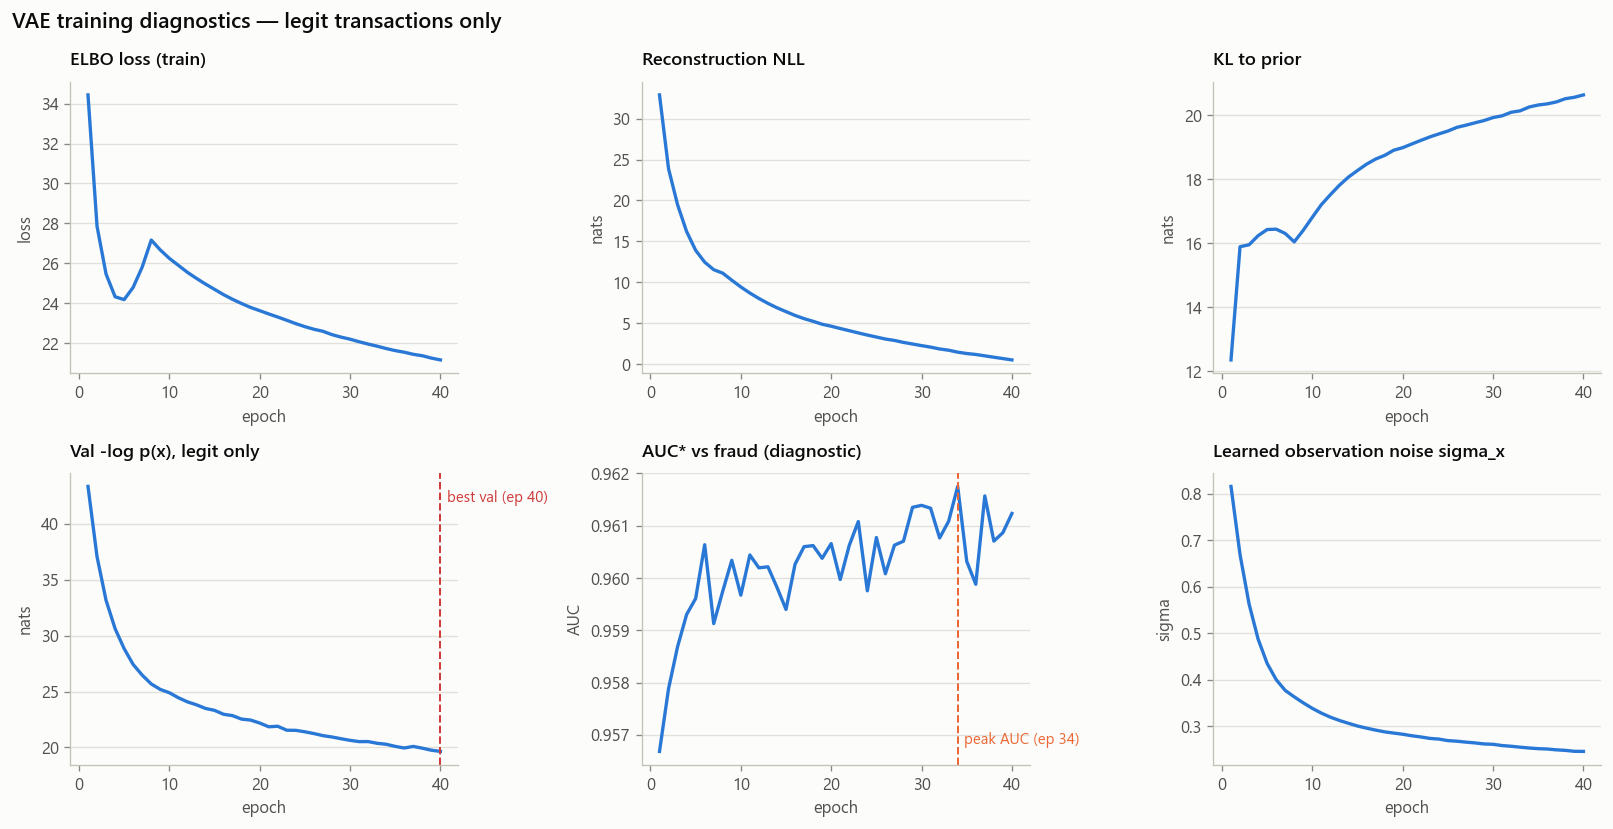

In [14]:
def plot_curves(hist):
    e = hist["epoch"]
    panels = [("train", "ELBO loss (train)", "loss"),
              ("nll", "Reconstruction NLL", "nats"),
              ("kl", "KL to prior", "nats"),
              ("val", "Val -log p(x), legit only", "nats"),
              ("auc", "AUC* vs fraud (diagnostic)", "AUC"),
              ("sigma_x", "Learned observation noise sigma_x", "sigma")]
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7))
    for ax, (k, title, ylab) in zip(axes.ravel(), panels):
        ax.plot(e, hist[k], color=C_LEGIT)
        ax.set(title=title, xlabel="epoch", ylabel=ylab)
        if k == "val":
            b = hist["epoch"][int(np.argmin(hist["val"]))]
            ax.axvline(b, color=C_THR, ls="--", lw=1.2)
            ax.annotate(f"best val (ep {b})", (b, max(hist["val"])),
                        color=C_THR, fontsize=9, ha="left", va="top",
                        xytext=(4, -2), textcoords="offset points")
        if k == "auc":
            pk = hist["epoch"][int(np.argmax(hist["auc"]))]
            ax.axvline(pk, color=C_FRAUD, ls="--", lw=1.2)
            ax.annotate(f"peak AUC (ep {pk})", (pk, min(hist["auc"])),
                        color=C_FRAUD, fontsize=9, ha="left", va="bottom",
                        xytext=(4, 2), textcoords="offset points")
    fig.suptitle("VAE training diagnostics — legit transactions only",
                 x=.008, ha="left", fontsize=13, fontweight="semibold")
    fig.tight_layout(); plt.show()

plot_curves(hist)


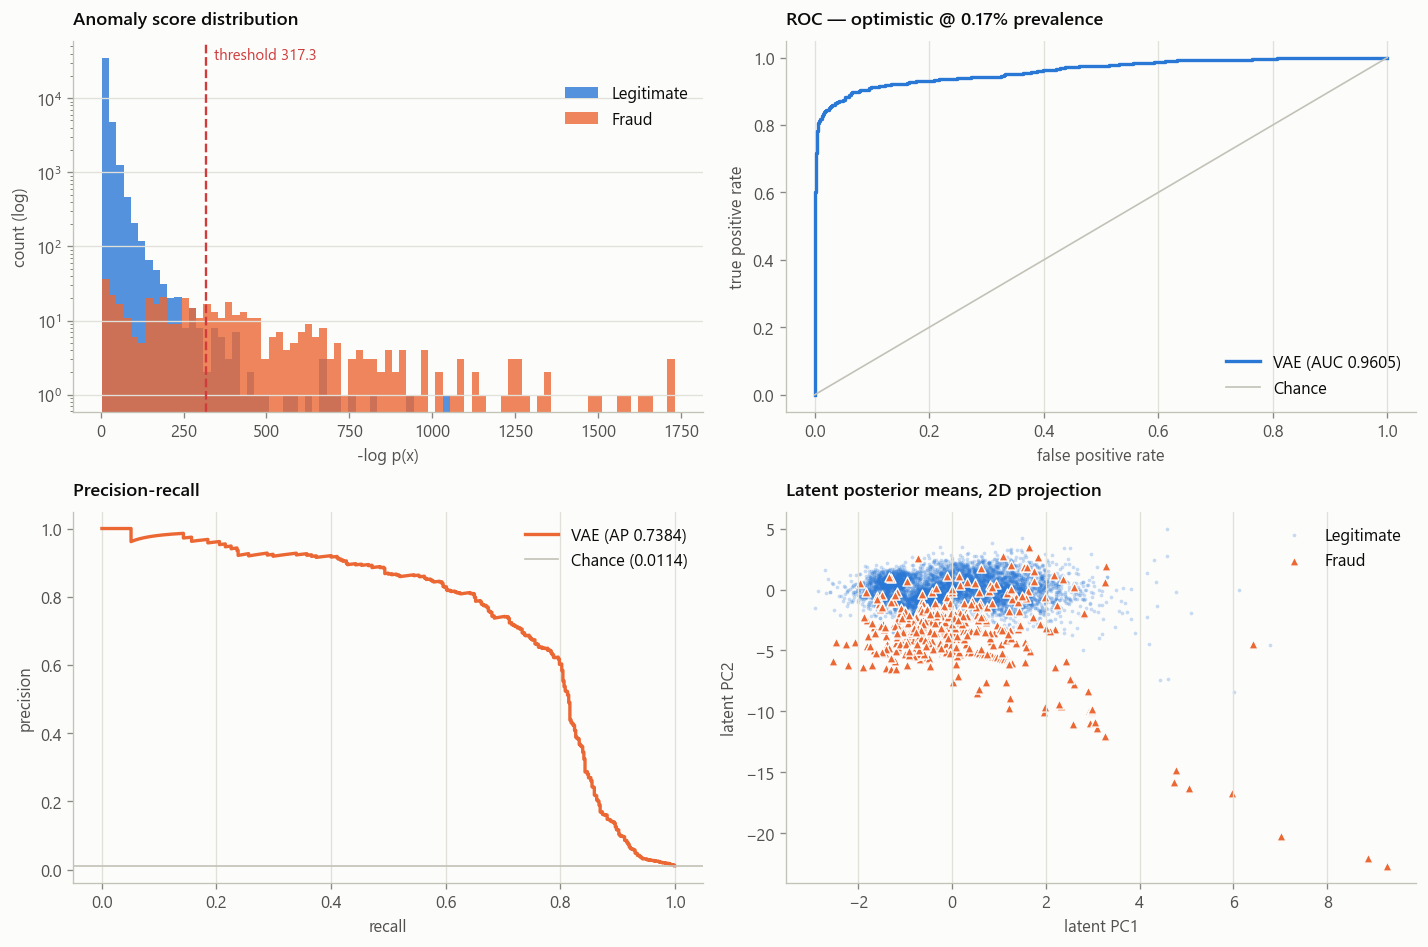

In [15]:
def plot_detection(model, sp, S, fpr_budget=0.001):
    thr = np.percentile(S["va"], 100 * (1 - fpr_budget))
    fig, ax = plt.subplots(2, 2, figsize=(12, 8))

    lo, hi = np.percentile(S["scores"], [.5, 99.9])
    bins = np.linspace(lo, hi, 80)
    ax[0,0].hist(S["te_n"], bins=bins, color=C_LEGIT, alpha=.8, label="Legitimate")
    ax[0,0].hist(S["te_a"], bins=bins, color=C_FRAUD, alpha=.8, label="Fraud")
    ax[0,0].axvline(thr, color=C_THR, ls="--", lw=1.4)
    ax[0,0].set(yscale="log", title="Anomaly score distribution",
                xlabel="-log p(x)", ylabel="count (log)")
    # pin the label to the top of the axes so it never lands on the bars
    ax[0,0].annotate(f"threshold {thr:.1f}", xy=(thr, 1),
                     xycoords=("data", "axes fraction"),
                     xytext=(5, -4), textcoords="offset points",
                     color=C_THR, fontsize=9, ha="left", va="top")
    ax[0,0].legend(loc="upper right", bbox_to_anchor=(1.0, 0.92))

    fpr, tpr, _ = roc_curve(S["labels"], S["scores"])
    ax[0,1].plot(fpr, tpr, color=C_LEGIT, label=f"VAE (AUC {roc_auc_score(S['labels'], S['scores']):.4f})")
    ax[0,1].plot([0,1], [0,1], color=AXLINE, lw=1, label="Chance")
    ax[0,1].set(title="ROC — optimistic @ 0.17% prevalence",
                xlabel="false positive rate", ylabel="true positive rate")
    ax[0,1].grid(axis="both"); ax[0,1].legend(loc="lower right")

    pr, rc, _ = precision_recall_curve(S["labels"], S["scores"])
    ap = average_precision_score(S["labels"], S["scores"])
    base = S["labels"].mean()
    ax[1,0].plot(rc, pr, color=C_FRAUD, label=f"VAE (AP {ap:.4f})")
    ax[1,0].axhline(base, color=AXLINE, lw=1, label=f"Chance ({base:.4f})")
    ax[1,0].set(title="Precision-recall ",
                xlabel="recall", ylabel="precision")
    ax[1,0].grid(axis="both"); ax[1,0].legend(loc="upper right")

    with torch.no_grad():
        mn = model.encode(sp["te_n"][:6000].to(DEVICE))[0].cpu().numpy()
        ma = model.encode(sp["te_a"].to(DEVICE))[0].cpu().numpy()
    q = PCA(n_components=2, random_state=SEED).fit(mn)
    An, Aa = q.transform(mn), q.transform(ma)
    ax[1,1].scatter(*An.T, s=5, c=C_LEGIT, alpha=.25, lw=0, label="Legitimate")
    ax[1,1].scatter(*Aa.T, s=30, c=C_FRAUD, marker="^", lw=.8,
                    edgecolor=SURFACE, label="Fraud")
    ax[1,1].set(title="Latent posterior means, 2D projection",
                xlabel="latent PC1", ylabel="latent PC2")
    ax[1,1].grid(axis="both"); ax[1,1].legend()

    fig.tight_layout(); plt.show()
    return thr

thr = plot_detection(model, sp, S)


In [16]:
rows = []
for p in (95, 99, 99.5, 99.9, 99.95, 99.99):
    t = np.percentile(S["va"], p)
    tp, fp = int((S["te_a"] > t).sum()), int((S["te_n"] > t).sum())
    rec = tp / len(S["te_a"])
    prec = tp / (tp + fp) if tp + fp else 0.0
    f1 = 2*prec*rec/(prec+rec) if prec+rec else 0.0
    rows.append((p, t, rec, prec, f1, tp, fp))

print(f"{'pct':>6} {'thr':>9} {'recall':>7} {'prec':>7} {'F1':>6} {'TP':>5} {'FP':>6}")
for p, t, rec, prec, f1, tp, fp in rows:
    print(f"{p:6.2f} {t:9.2f} {rec:7.3f} {prec:7.3f} {f1:6.3f} {tp:5d} {fp:6d}")


   pct       thr  recall    prec     F1    TP     FP
 95.00     49.65   0.870   0.171  0.285   428   2079
 99.00    112.10   0.815   0.510  0.627   401    386
 99.50    154.72   0.768   0.653  0.706   378    201
 99.90    317.33   0.553   0.863  0.674   272     43
 99.95    420.43   0.411   0.918  0.567   202     18
 99.99    808.60   0.191   0.959  0.319    94      4


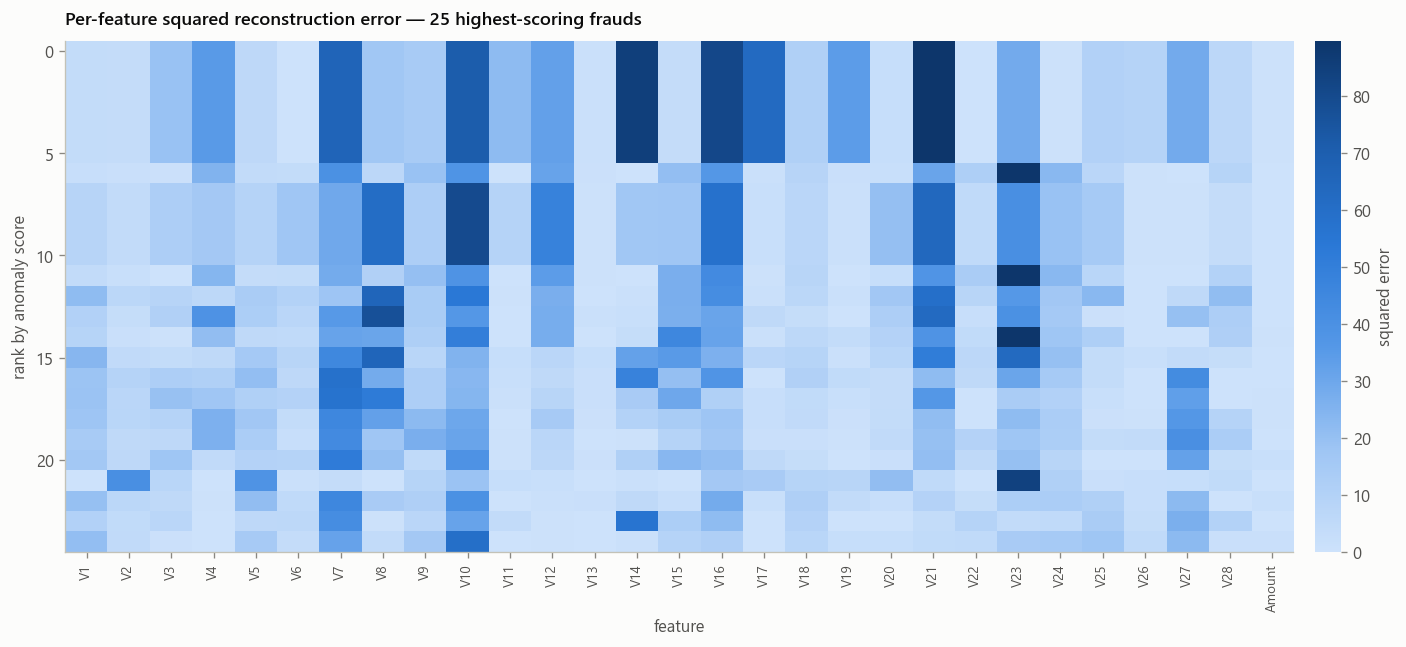

In [17]:
K = 25
# .copy() because torch cannot index with a negative-stride array
idx = np.argsort(S["te_a"])[-K:][::-1].copy()
with torch.no_grad():
    xa = sp["te_a"][idx].to(DEVICE)
    err = ((xa - model.decode(model.encode(xa)[0])) ** 2).cpu().numpy()

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(err, aspect="auto", cmap=BLUE_RAMP,
               vmin=0, vmax=np.percentile(err, 99))
ax.set(title=f"Per-feature squared reconstruction error — {K} highest-scoring frauds",
       xlabel="feature", ylabel="rank by anomaly score")
ax.set_xticks(range(len(sp["cols"])), sp["cols"], rotation=90, fontsize=8)
ax.grid(False)
# plt.setp, not cb.outline.set_visible(...): matplotlib's _ColorbarSpine stub
# makes Pylance flag any direct method call on it
cb = fig.colorbar(im, ax=ax, pad=.015); plt.setp(cb.outline, visible=False)
cb.set_label("squared error", color=INK2)
fig.tight_layout(); plt.show()


In [18]:
from sklearn.ensemble import IsolationForest

# one-class baseline: fit on clean held-out legit rows, same data the VAE
# calibrated its threshold on.
# max_samples: sklearn's 'auto' default is min(256, n) -- only 256 of 42,647
# rows per tree, which badly underfits 29 dimensions. 16384 is the fair setting.
# type: ignore -- sklearn's stub types max_samples as str, but int is valid.
iso = IsolationForest(n_estimators=300, contamination="auto",
                      random_state=SEED, n_jobs=-1,
                      max_samples=16384).fit(sp["va"].numpy())  # type: ignore[arg-type]
b = -np.r_[iso.score_samples(sp["te_n"].numpy()), iso.score_samples(sp["te_a"].numpy())]
print(f"VAE     AUC {roc_auc_score(S['labels'], S['scores']):.4f} | "
      f"AP {average_precision_score(S['labels'], S['scores']):.4f}")
print(f"iForest AUC {roc_auc_score(S['labels'], b):.4f} | "
      f"AP {average_precision_score(S['labels'], b):.4f}")


VAE     AUC 0.9605 | AP 0.7384
iForest AUC 0.9599 | AP 0.6272


In [19]:

# TUNING 
#
# Protocol: hyperparameters are chosen on a SELECTION slice of the labelled
# test data; the winner is then reported on a disjoint FINAL slice the search
# never touched.  Selecting on val -logp alone does NOT work here -- more
# capacity always fits the legit density better while detection stays flat
# (the 40-epoch run improved val -logp by 55% and AUC* by 0.5%).

import contextlib, io, time
from typing import Any

DATA_CACHE = make_data()        # load the 150 MB CSV once, reuse for every run
SEL_FRAC   = 0.40               # share of labelled test data used for SELECTION

_nl     = len(DATA_CACHE[0])
_n_te_n = _nl - int(.7 * _nl) - int(.15 * _nl)
_n_te_a = len(DATA_CACHE[1])

_rs    = np.random.default_rng(20240930)
MASK_N = _rs.random(_n_te_n) < SEL_FRAC      # True -> selection, False -> final
MASK_A = _rs.random(_n_te_a) < SEL_FRAC
print(f"selection slice: {MASK_N.sum():>6} legit + {MASK_A.sum():>3} fraud")
print(f"final slice    : {(~MASK_N).sum():>6} legit + {(~MASK_A).sum():>3} fraud")


def _ap_auc(scores_n, scores_a):
    s = np.r_[scores_n, scores_a]
    y = np.r_[np.zeros(len(scores_n)), np.ones(len(scores_a))]
    return average_precision_score(y, s), roc_auc_score(y, s)


def run_config(latent=12, hidden=(128, 64), lr=1e-3, batch=512,
               warmup=8, epochs=25, seed=SEED, L=64):
    """One training run, silenced. Returns a dict of metrics."""
    torch.manual_seed(seed); np.random.seed(seed)
    t0 = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()):          # hide the epoch log
        model, hist, sp = train_vae(epochs=epochs, warmup=warmup, hidden=hidden,
                                    latent=latent, lr=lr, batch=batch,
                                    data=DATA_CACHE)
        S       = evaluate(model, sp, L=L)
        kl_dims = per_dim_kl(model, sp["va"])

    ap_sel, _       = _ap_auc(S["te_n"][MASK_N],  S["te_a"][MASK_A])
    ap_fin, auc_fin = _ap_auc(S["te_n"][~MASK_N], S["te_a"][~MASK_A])
    return dict(latent=latent, hidden=hidden, lr=lr, batch=batch, epochs=epochs,
                params=sum(p.numel() for p in model.parameters()),
                val=min(hist["val"]), best_ep=sp["best_ep"],
                alive=sum(v > 0.05 for v in kl_dims),
                ap_sel=ap_sel, ap_final=ap_fin, auc_final=auc_fin,
                secs=time.perf_counter() - t0)


selection slice:  17080 legit + 205 fraud
final slice    :  25568 legit + 287 fraud


In [20]:
# ---- the sweep ---------------------------------------------------------------
# latent is the real knob (your run had all 12 dims alive -> try bigger).
# ~55-80 s per config on CPU; 8 configs is roughly 8-10 minutes.
# Trim TUNE_GRID or drop epochs to 15 for a faster first pass.
# NOTE: named TUNE_GRID, not GRID -- GRID is already a chart colour in cell 1.

TUNE_GRID: list[dict[str, Any]] = ([dict(latent=k) for k in (4, 8, 12, 16, 24, 32)] +
        [dict(latent=16, hidden=(256, 128)),
         dict(latent=16, hidden=(64, 32))])

res = []
for i, cfg in enumerate(TUNE_GRID, 1):
    r = run_config(epochs=25, **cfg)
    res.append(r)
    print(f"[{i}/{len(TUNE_GRID)}] latent={r['latent']:<3} hidden={str(r['hidden']):<11} "
          f"alive={r['alive']:>2}/{r['latent']:<3} val={r['val']:8.2f} "
          f"AP_sel={r['ap_sel']:.4f}  ({r['secs']:.0f}s)")

df = pd.DataFrame(res).sort_values("ap_sel", ascending=False)
print("\n--- ranked by SELECTION-slice AP (the honest criterion) ---")
print(df[["latent", "hidden", "params", "alive", "val", "best_ep",
          "ap_sel", "ap_final", "auc_final"]].to_string(index=False))


[1/8] latent=4   hidden=(128, 64)   alive= 4/4   val=   32.34 AP_sel=0.6377  (144s)
[2/8] latent=8   hidden=(128, 64)   alive= 8/8   val=   26.36 AP_sel=0.7207  (96s)
[3/8] latent=12  hidden=(128, 64)   alive=12/12  val=   21.40 AP_sel=0.7877  (91s)
[4/8] latent=16  hidden=(128, 64)   alive=16/16  val=   17.55 AP_sel=0.7699  (113s)
[5/8] latent=24  hidden=(128, 64)   alive=20/24  val=   14.55 AP_sel=0.8010  (120s)
[6/8] latent=32  hidden=(128, 64)   alive=23/32  val=   10.76 AP_sel=0.7816  (123s)
[7/8] latent=16  hidden=(256, 128)  alive=16/16  val=   14.04 AP_sel=0.7608  (141s)
[8/8] latent=16  hidden=(64, 32)    alive=14/16  val=   25.20 AP_sel=0.7757  (89s)

--- ranked by SELECTION-slice AP (the honest criterion) ---
 latent     hidden  params  alive       val  best_ep   ap_sel  ap_final  auc_final
     24  (128, 64)   28878     20 14.550759       25 0.801015  0.794492   0.952261
     12  (128, 64)   26550     12 21.395994       25 0.787715  0.774873   0.957543
     32  (128, 64)   

selector                   config                      FINAL AP  FINAL AUC
SELECTION-slice AP         latent=24 hidden=(128, 64)    0.7945     0.9523
val -logp only             latent=32 hidden=(128, 64)    0.7673     0.9445
notebook default           latent=12 hidden=(128, 64)    0.7749     0.9575

val -logp ranks configs by density fit, which rewards capacity:
 latent     hidden       val  ap_final
     32  (128, 64) 10.761599  0.767338
     16 (256, 128) 14.037174  0.754591
     24  (128, 64) 14.550759  0.794492
     16  (128, 64) 17.545067  0.771656
     12  (128, 64) 21.395994  0.774873
     16   (64, 32) 25.201118  0.773188
      8  (128, 64) 26.357288  0.711268
      4  (128, 64) 32.337814  0.604156

retraining winner at 40 epochs: {'latent': 24, 'hidden': (128, 64), 'lr': 0.001, 'batch': 512}

train 199020 | val 42647 | test-legit 42648 | test-fraud 492
389 steps/epoch -> 15560 total updates
ep   1 | beta 0.12 | train     34.45 | nll    32.69 | kl 14.13 | val -logp    46.56 | s

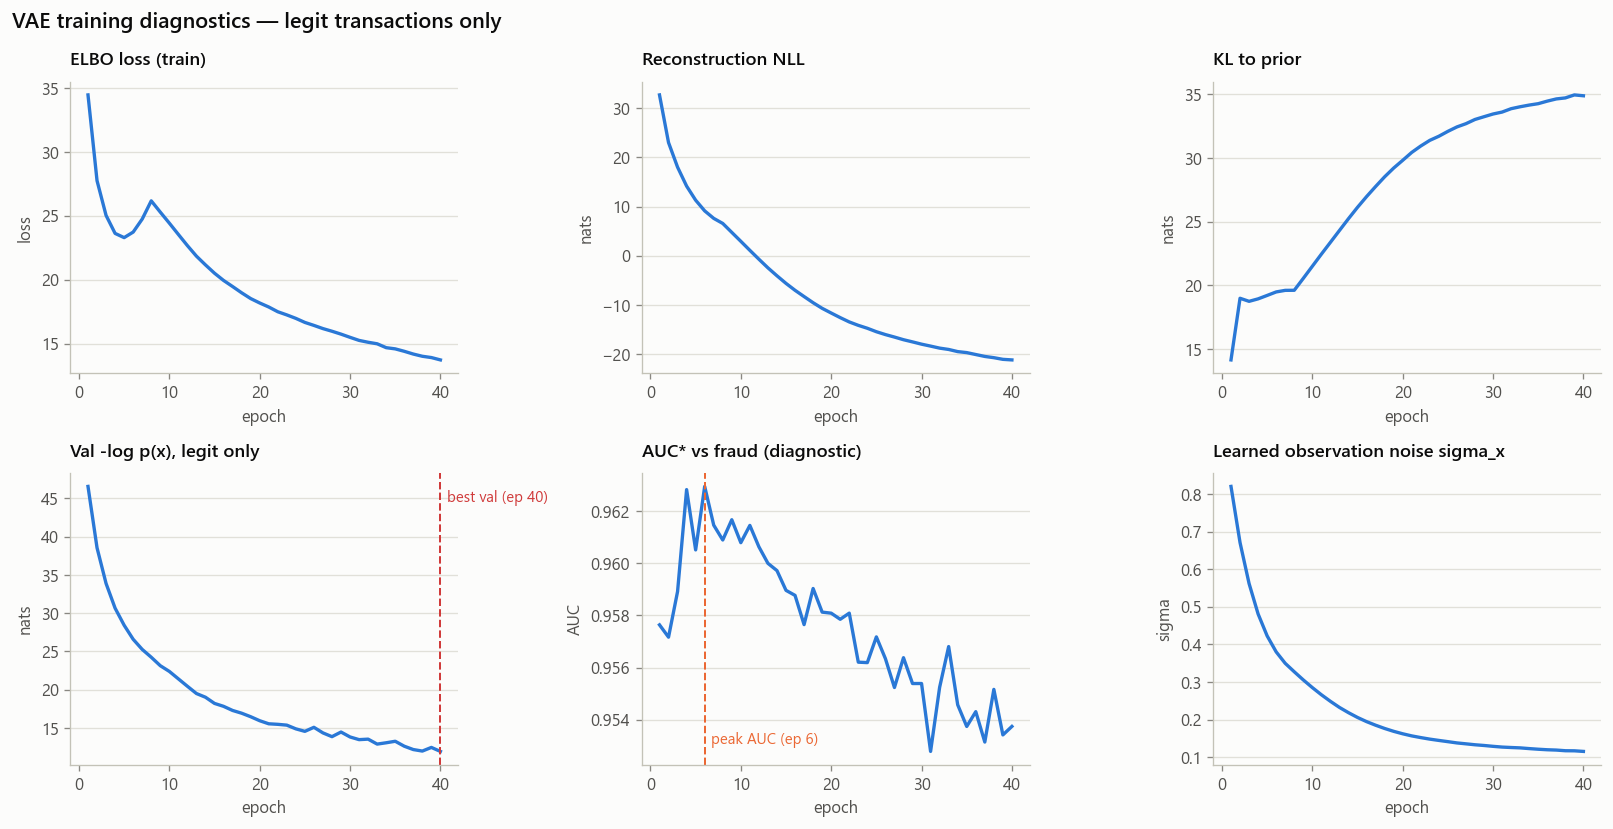

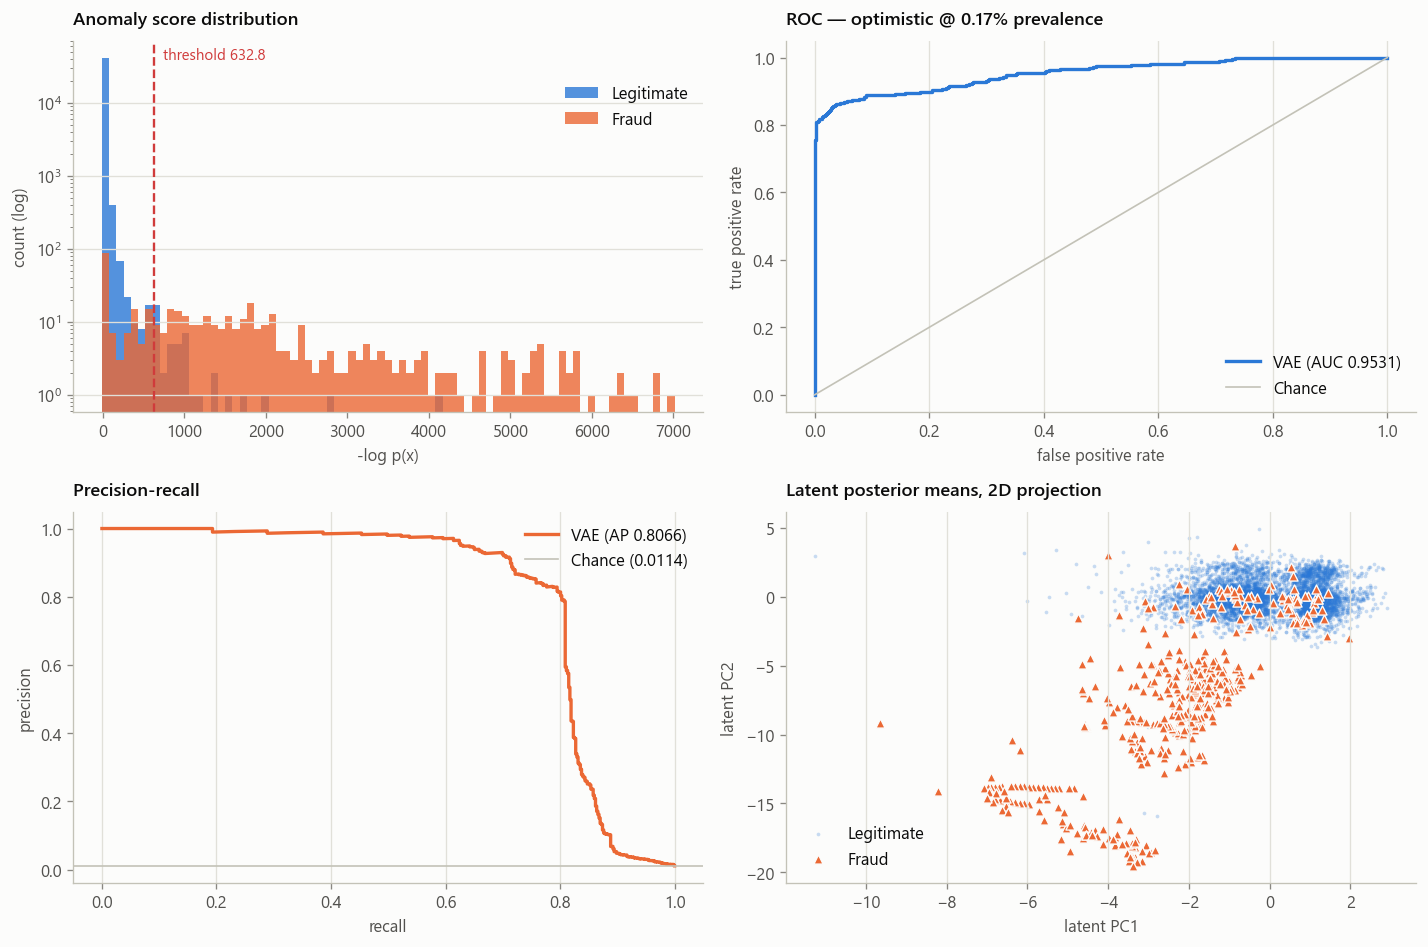

In [21]:
# ---- pick the winner, and show why val -logp is the wrong selector -----------
best_ap  = df.iloc[0]                       # chosen on SELECTION-slice AP
best_val = df.sort_values("val").iloc[0]    # chosen on val -logp alone (label-free)
base     = next(r for r in res if r["latent"] == 12 and r["hidden"] == (128, 64))

print(f"{'selector':<26} {'config':<26} {'FINAL AP':>9} {'FINAL AUC':>10}")
for name, r in (("SELECTION-slice AP", best_ap),
                ("val -logp only", best_val),
                ("notebook default", base)):
    cfg = f"latent={r['latent']} hidden={r['hidden']}"
    print(f"{name:<26} {cfg:<26} {r['ap_final']:>9.4f} {r['auc_final']:>10.4f}")

print("\nval -logp ranks configs by density fit, which rewards capacity:")
print(df.sort_values("val")[["latent", "hidden", "val", "ap_final"]].to_string(index=False))

# ---- retrain the winner at full length, then reuse the existing plots --------
BEST: dict[str, Any] = dict(latent=int(best_ap["latent"]), hidden=best_ap["hidden"],
                            lr=float(best_ap["lr"]), batch=int(best_ap["batch"]))
print(f"\nretraining winner at 40 epochs: {BEST}\n")
torch.manual_seed(SEED); np.random.seed(SEED)
model_t, hist_t, sp_t = train_vae(epochs=40, data=DATA_CACHE, **BEST)
S_t = evaluate(model_t, sp_t)

print(f"\ntuned    AUC {roc_auc_score(S_t['labels'], S_t['scores']):.4f} | "
      f"AP {average_precision_score(S_t['labels'], S_t['scores']):.4f}")
print(f"original AUC {roc_auc_score(S['labels'], S['scores']):.4f} | "
      f"AP {average_precision_score(S['labels'], S['scores']):.4f}   (latent=12)")
print("\nKL per latent dim:", [round(v, 2) for v in per_dim_kl(model_t, sp_t['va'])])

# the existing figures work on the tuned model too:
plot_curves(hist_t)
thr_t = plot_detection(model_t, sp_t, S_t)


In [22]:
# ---- fine sweep: latent 18-22, multi-seed ------------------------------------
# Why: the latent=24 winner had 4 dimensions collapsed to exactly 0.0 KL, so the
# natural dimensionality of the legit manifold sits just below 24. 12 and 24 are
# included as anchors so the comparison is like-for-like (same seeds).
# Why 3 seeds: the single-seed gaps in the coarse sweep (~0.02 AP) sit right at
# the noise floor, so one run cannot rank these.
#
# RUNTIME: 7 latents x 3 seeds = 21 runs, roughly 20-25 min on CPU.
# To halve it, drop the anchors -> FINE_LATENTS = (18, 19, 20, 21, 22)

FINE_LATENTS = (12, 18, 19, 20, 21, 22, 24)
SEEDS = (0, 1, 2)

fine = []
for lat in FINE_LATENTS:
    for sd in SEEDS:
        r = run_config(epochs=25, latent=lat, seed=sd)
        r["seed"] = sd
        fine.append(r)
        print(f"latent {r['latent']:>2} seed {sd} | alive {r['alive']:>2}/{r['latent']:<2} "
              f"| val {r['val']:7.2f} | AP_sel {r['ap_sel']:.4f} | AP_fin {r['ap_final']:.4f} "
              f"| AUC {r['auc_final']:.4f}  ({r['secs']:.0f}s)")

fdf = pd.DataFrame(fine)
agg = fdf.groupby("latent").agg(alive=("alive", "mean"), val=("val", "mean"),
                                ap_sel=("ap_sel", "mean"), ap_sel_sd=("ap_sel", "std"),
                                ap_final=("ap_final", "mean"), ap_final_sd=("ap_final", "std"),
                                auc=("auc_final", "mean")).round(4)
agg.insert(1, "dead", agg.index - agg["alive"])     # collapsed dims = latent - alive
print(f"\n--- mean over {len(SEEDS)} seeds ---")
print(agg.to_string())

pooled_sd = fdf.groupby("latent").ap_final.std().mean()
print(f"\npooled across-seed AP sd: {pooled_sd:.4f}  "
      f"-> gaps smaller than ~{2*pooled_sd:.3f} are not evidence")

best_l = agg.ap_sel.idxmax()
print(f"\nbest by SELECTION AP : latent={best_l}  -> FINAL AP {agg.loc[best_l,'ap_final']:.4f} "
      f"+/- {agg.loc[best_l,'ap_final_sd']:.4f}")
for anchor in (12, 24):                             # skipped if you trimmed FINE_LATENTS
    if anchor in agg.index:
        print(f"latent={anchor} anchor     :  FINAL AP {agg.loc[anchor,'ap_final']:.4f}")


latent 12 seed 0 | alive 12/12 | val   21.19 | AP_sel 0.7564 | AP_fin 0.7498 | AUC 0.9560  (129s)
latent 12 seed 1 | alive 12/12 | val   22.48 | AP_sel 0.7300 | AP_fin 0.7249 | AUC 0.9554  (105s)
latent 12 seed 2 | alive 12/12 | val   20.71 | AP_sel 0.7548 | AP_fin 0.7438 | AUC 0.9485  (98s)
latent 18 seed 0 | alive 18/18 | val   15.98 | AP_sel 0.7839 | AP_fin 0.7688 | AUC 0.9470  (100s)
latent 18 seed 1 | alive 18/18 | val   16.05 | AP_sel 0.7824 | AP_fin 0.7793 | AUC 0.9553  (102s)
latent 18 seed 2 | alive 18/18 | val   14.48 | AP_sel 0.7711 | AP_fin 0.7625 | AUC 0.9480  (99s)
latent 19 seed 0 | alive 19/19 | val   13.80 | AP_sel 0.7919 | AP_fin 0.7833 | AUC 0.9505  (149s)
latent 19 seed 1 | alive 19/19 | val   14.03 | AP_sel 0.7393 | AP_fin 0.7477 | AUC 0.9495  (266s)
latent 19 seed 2 | alive 19/19 | val   14.19 | AP_sel 0.7762 | AP_fin 0.7627 | AUC 0.9516  (104s)
latent 20 seed 0 | alive 19/20 | val   15.32 | AP_sel 0.7509 | AP_fin 0.7487 | AUC 0.9500  (102s)
latent 20 seed 1 | ali